In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

print("Libraries imported successfully!")
print("OpenCV Version:", cv2.__version__)

Libraries imported successfully!
OpenCV Version: 4.10.0


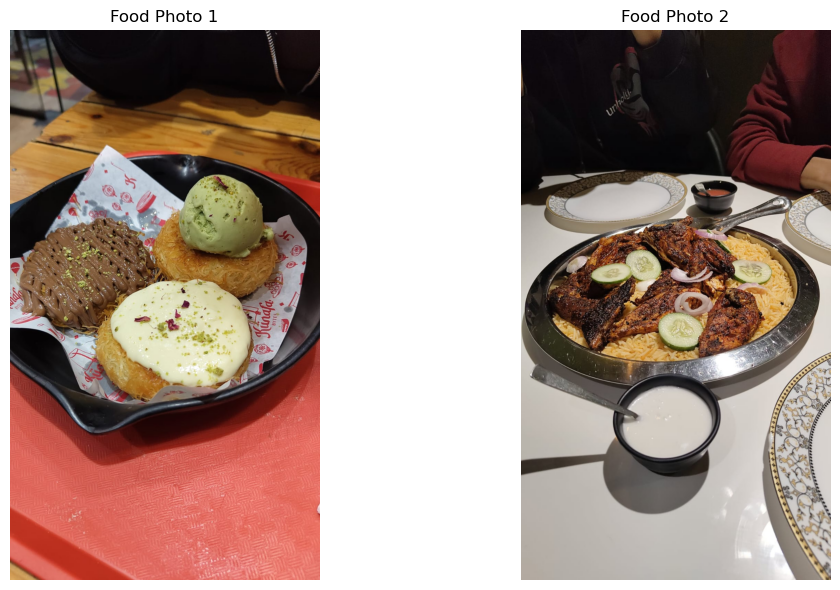

Photo 1 dimensions: (1599, 899, 3)
Photo 2 dimensions: (1599, 899, 3)


In [3]:
# Set project and dataset paths
PROJECT_DIR = Path.cwd()
DATASET_DIR = PROJECT_DIR / "dataset"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "task3_object_recognition"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load food images
image1_path = DATASET_DIR / "food_photo_1.jpg"
image2_path = DATASET_DIR / "food_photo_2.jpg"

image1 = cv2.imread(str(image1_path))
image2 = cv2.imread(str(image2_path))

# Check image loading
if image1 is None or image2 is None:
    raise FileNotFoundError(
        "Food photos not found. Check filenames and extensions."
    )

# Convert images to RGB
image1_rgb = cv2.cvtColor(image1, cv2.COLOR_BGR2RGB)
image2_rgb = cv2.cvtColor(image2, cv2.COLOR_BGR2RGB)

# Display both images
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(image1_rgb)
plt.title("Food Photo 1")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image2_rgb)
plt.title("Food Photo 2")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Photo 1 dimensions:", image1.shape)
print("Photo 2 dimensions:", image2.shape)

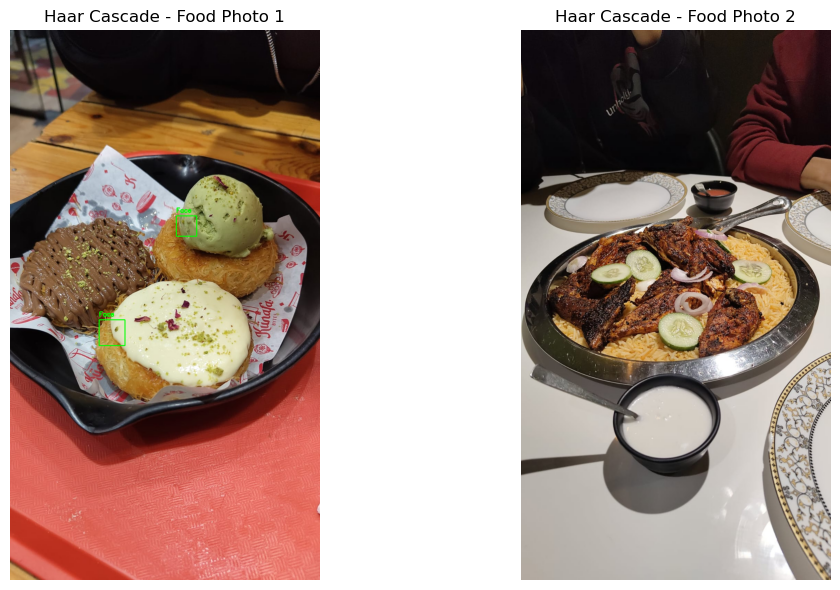

Photo 1 detections: 2
Photo 2 detections: 0


In [5]:
# Load pretrained Haar Cascade classifier
cascade_path = cv2.data.haarcascades + "haarcascade_frontalface_default.xml"

haar_cascade = cv2.CascadeClassifier(cascade_path)

if haar_cascade.empty():
    raise FileNotFoundError("Haar Cascade classifier could not be loaded.")

def detect_with_haar(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    detections = haar_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(30, 30)
    )

    result = image.copy()

    for (x, y, w, h) in detections:
        cv2.rectangle(
            result,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

        cv2.putText(
            result,
            "Face",
            (x, y - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 0),
            2
        )

    return result, detections

# Detect in both food photos
haar_result1, haar_detections1 = detect_with_haar(image1)
haar_result2, haar_detections2 = detect_with_haar(image2)

# Display results
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(haar_result1, cv2.COLOR_BGR2RGB))
plt.title("Haar Cascade - Food Photo 1")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(haar_result2, cv2.COLOR_BGR2RGB))
plt.title("Haar Cascade - Food Photo 2")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Photo 1 detections:", len(haar_detections1))
print("Photo 2 detections:", len(haar_detections2))

In [1]:
%pip install ultralytics --user

  Using cached ultralytics-8.4.201-py3-none-any.whl.metadata (47 kB)
  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
  Using cached torchvision-0.29.2-py3-none-win_amd64.whl.metadata (5.7 kB)
  Using cached ultralytics_thop-2.2.4-py3-none-any.whl.metadata (14 kB)
  Using cached ultralytics_platform-0.1.102-py3-none-any.whl.metadata (17 kB)
  Using cached httpx-0.28.1-py3-none-any.whl.metadata (7.1 kB)
Using cached ultralytics-8.4.201-py3-none-any.whl (1.4 MB)
Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl (44.0 MB)
Using cached torchvision-0.29.2-py3-none-win_amd64.whl (1.4 MB)
Using cached ultralytics_platform-0.1.102-py3-none-any.whl (100 kB)
Using cached ultralytics_thop-2.2.4-py3-none-any.whl (32 kB)
Using cached httpx-0.28.1-py3-none-any.whl (73 kB)
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [1]:
import ultralytics

print("Ultralytics version:", ultralytics.__version__)

Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\ahada\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics version: 8.4.201


In [3]:
from ultralytics import YOLO

# Load pretrained YOLOv8 Nano model
model = YOLO("yolov8n.pt")

print("YOLO model loaded successfully!")

YOLO model loaded successfully!


In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from ultralytics import YOLO

print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)
print("Environment working successfully!")

NumPy: 1.26.4
OpenCV: 4.10.0
Environment working successfully!


In [2]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from ultralytics import YOLO

# Project paths
PROJECT_DIR = Path.cwd()
DATASET_DIR = PROJECT_DIR / "dataset"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "task3_object_recognition"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load food images
image1 = cv2.imread(str(DATASET_DIR / "food_photo_1.jpg"))
image2 = cv2.imread(str(DATASET_DIR / "food_photo_2.jpg"))

if image1 is None or image2 is None:
    raise FileNotFoundError("Food photos could not be loaded. Check filenames.")

print("Both food photos loaded successfully!")

Both food photos loaded successfully!


In [3]:
model = YOLO("yolov8n.pt")

print("YOLOv8 model loaded successfully!")

YOLOv8 model loaded successfully!



0: 640x384 1 handbag, 1 dining table, 164.6ms
Speed: 13.3ms preprocess, 164.6ms inference, 22.9ms postprocess per image at shape (1, 3, 640, 384)

0: 640x384 2 persons, 1 fork, 2 bowls, 1 dining table, 49.0ms
Speed: 27.1ms preprocess, 49.0ms inference, 2.4ms postprocess per image at shape (1, 3, 640, 384)


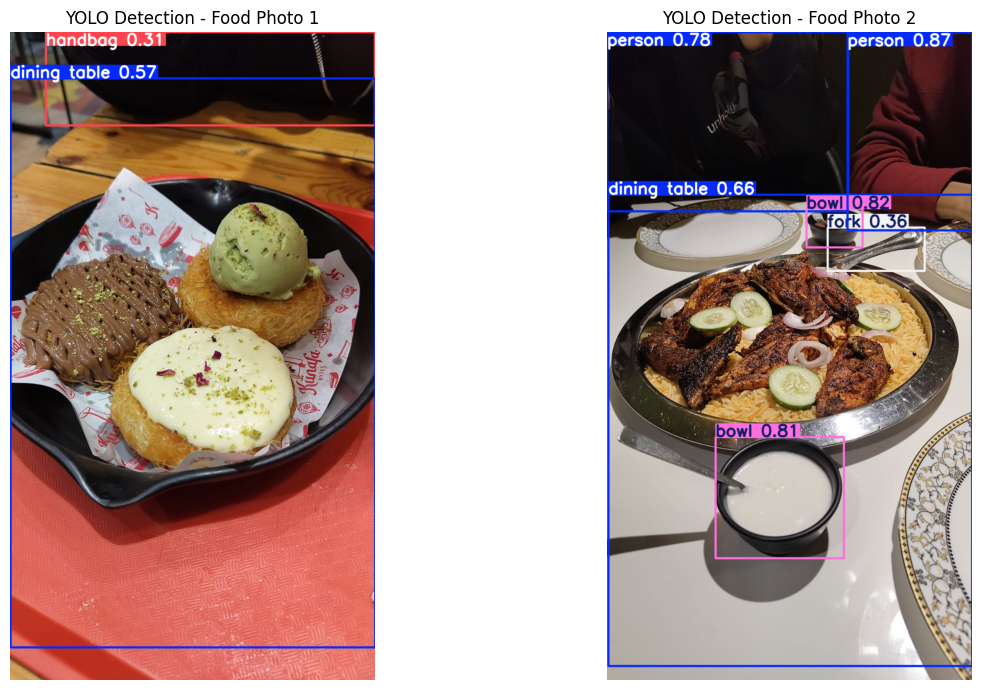

In [4]:
# Run YOLO detection
results1 = model(image1, conf=0.25)
results2 = model(image2, conf=0.25)

# Generate annotated images
yolo_result1 = results1[0].plot()
yolo_result2 = results2[0].plot()

# Convert BGR to RGB
yolo_result1_rgb = cv2.cvtColor(yolo_result1, cv2.COLOR_BGR2RGB)
yolo_result2_rgb = cv2.cvtColor(yolo_result2, cv2.COLOR_BGR2RGB)

# Display results
plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
plt.imshow(yolo_result1_rgb)
plt.title("YOLO Detection - Food Photo 1")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(yolo_result2_rgb)
plt.title("YOLO Detection - Food Photo 2")
plt.axis("off")

plt.tight_layout()
plt.show()

In [5]:
def display_detections(results, image_name):
    print(f"\n{image_name}")

    for result in results:
        for box in result.boxes:
            class_id = int(box.cls[0])
            confidence = float(box.conf[0])
            label = model.names[class_id]

            print(
                f"Object: {label} | "
                f"Confidence: {confidence:.2f}"
            )

display_detections(results1, "Food Photo 1")
display_detections(results2, "Food Photo 2")


Food Photo 1
Object: dining table | Confidence: 0.57
Object: handbag | Confidence: 0.31

Food Photo 2
Object: person | Confidence: 0.87
Object: bowl | Confidence: 0.82
Object: bowl | Confidence: 0.81
Object: person | Confidence: 0.78
Object: dining table | Confidence: 0.66
Object: fork | Confidence: 0.36


In [6]:
# Save YOLO detection outputs
cv2.imwrite(
    str(OUTPUT_DIR / "yolo_food_photo1.png"),
    yolo_result1
)

cv2.imwrite(
    str(OUTPUT_DIR / "yolo_food_photo2.png"),
    yolo_result2
)

print("YOLO detection images saved successfully!")

YOLO detection images saved successfully!


In [8]:
print([name for name in globals() if "haar" in name.lower()])

[]


In [9]:
# Load OpenCV's pretrained Haar Cascade
haar_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

# Convert food images to grayscale
gray1 = cv2.cvtColor(image1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(image2, cv2.COLOR_BGR2GRAY)

# Detect faces
haar_detections1 = haar_cascade.detectMultiScale(
    gray1, scaleFactor=1.1, minNeighbors=5
)

haar_detections2 = haar_cascade.detectMultiScale(
    gray2, scaleFactor=1.1, minNeighbors=5
)

print("Food Photo 1 Haar detections:", len(haar_detections1))
print("Food Photo 2 Haar detections:", len(haar_detections2))

Food Photo 1 Haar detections: 2
Food Photo 2 Haar detections: 0


In [10]:
# Count detections
yolo_count1 = len(results1[0].boxes)
yolo_count2 = len(results2[0].boxes)

haar_count1 = len(haar_detections1)
haar_count2 = len(haar_detections2)

comparison_df = pd.DataFrame({
    "Method": ["Haar Cascade", "YOLOv8"],
    "Food Photo 1 Detections": [haar_count1, yolo_count1],
    "Food Photo 2 Detections": [haar_count2, yolo_count2]
})

display(comparison_df)

comparison_df.to_csv(
    OUTPUT_DIR / "object_detection_comparison.csv",
    index=False
)

,Method,Food Photo 1 Detections,Food Photo 2 Detections
0,Haar Cascade,2,0
1,YOLOv8,2,6


In [11]:
observations = """
Task 3: Object Recognition

Haar Cascade detected 2 regions in Food Photo 1 and 0 in Food Photo 2.
YOLOv8 detected 2 objects in Food Photo 1 and 6 in Food Photo 2.

YOLOv8 detected more objects than Haar Cascade in these images.
Haar Cascade is designed for specific patterns such as faces,
while YOLOv8 supports multiple object categories.

The results show that detection performance depends on the
model and the type of objects present in the images.
More detections do not necessarily indicate higher accuracy.
"""

with open(OUTPUT_DIR / "task3_observations.txt", "w") as file:
    file.write(observations)

print("Task 3 observations saved successfully!")

Task 3 observations saved successfully!
